Test Accuracy: 90.0%


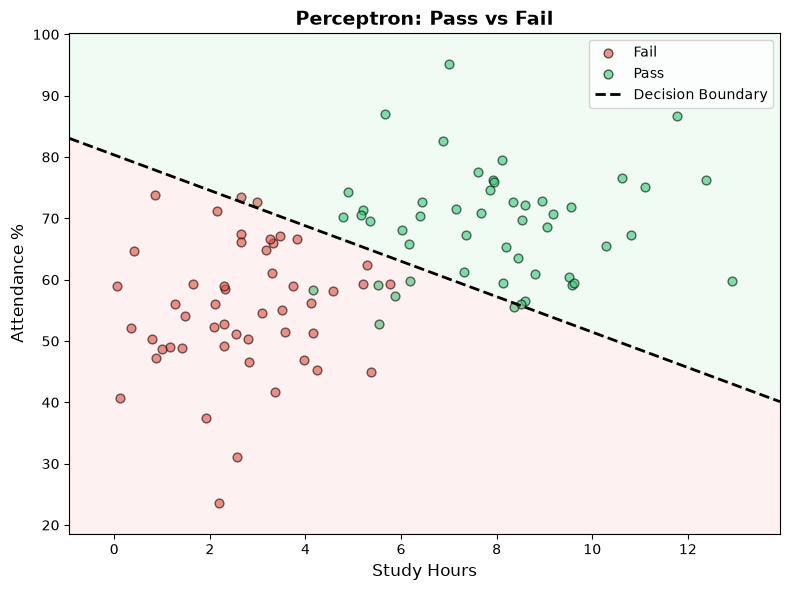

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --- Generate Data ---
np.random.seed(42)

fail_study  = np.random.normal(3, 1.5, 50)
fail_attend = np.random.normal(55, 12, 50)
pass_study  = np.random.normal(8, 2, 50)
pass_attend = np.random.normal(68, 10, 50)

X = np.vstack([
    np.column_stack([fail_study, fail_attend]),
    np.column_stack([pass_study, pass_attend])
])
y = np.array([0]*50 + [1]*50)

idx = np.random.permutation(100)
X, y = X[idx], y[idx]

# --- Normalize ---
split = 80
mean, std = X[:split].mean(0), X[:split].std(0)
X_train = (X[:split] - mean) / std
X_test  = (X[split:] - mean) / std
y_train, y_test = y[:split], y[split:]

# --- Perceptron ---
w, b = np.zeros(2), 0.0
lr = 0.1

for epoch in range(100):
    for xi, yi in zip(X_train[np.random.permutation(split)], y_train[np.random.permutation(split)]):
        pred = int(xi @ w + b >= 0)
        err = yi - pred
        w += lr * err * xi
        b += lr * err

# --- Evaluate ---
y_pred = (X_test @ w + b >= 0).astype(int)
acc = np.mean(y_pred == y_test)
print(f"Test Accuracy: {acc:.1%}")

# --- Plot ---
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(X[y==0, 0], X[y==0, 1], c='#e74c3c', label='Fail', alpha=0.6, edgecolors='k', s=40)
ax.scatter(X[y==1, 0], X[y==1, 1], c='#2ecc71', label='Pass', alpha=0.6, edgecolors='k', s=40)

# Decision boundary: w_norm · x_norm + b = 0
# Un-normalize: x_norm = (x - mean) / std
# w[0]*(x0 - m0)/s0 + w[1]*(x1 - m1)/s1 + b = 0
# Solve for x1:
xx = np.linspace(X[:,0].min()-1, X[:,0].max()+1, 200)
yy = mean[1] + (std[1]/w[1]) * (-(w[0]/std[0])*(xx - mean[0]) - b)

ax.plot(xx, yy, 'k--', linewidth=2, label='Decision Boundary')

# Shade the two regions
ax.fill_between(xx, yy, X[:,1].max()+5, color='#2ecc71', alpha=0.07)
ax.fill_between(xx, X[:,1].min()-5, yy, color='#e74c3c', alpha=0.07)

ax.set_xlabel('Study Hours', fontsize=12)
ax.set_ylabel('Attendance %', fontsize=12)
ax.set_title('Perceptron: Pass vs Fail', fontsize=14, fontweight='bold')
ax.set_xlim(X[:,0].min()-1, X[:,0].max()+1)
ax.set_ylim(X[:,1].min()-5, X[:,1].max()+5)
ax.legend()
plt.tight_layout()
plt.show()